# 08 · Advanced NLP: Word + Character TF-IDF

**Purpose:** improve the text classifier by combining **word** and **character** TF-IDF features, measure how stable the result is without tuning leakage, and apply the model to two practical tasks: suggesting categories for "Can't Tell" complaints and predicting new tweets.

**Questions answered**
- Do character n-grams add signal on top of word n-grams?
- How much do test scores vary across random splits when hyperparameters are re-tuned inside each training split?
- Does removing @handles hurt (i.e. was the model relying on airline identity)?
- Can a complaint-category model route "Can't Tell" complaints?

Notebook 10 improves this model further and produces the project's final model.

> **Labels vs predictions:** the descriptive analysis (notebooks 03–05) uses the sentiment labels supplied with the dataset. The models here *predict* those labels from text, for evaluation and for new tweets. Predictions never replace the supplied labels.

## 0. Setup

In [1]:
import sys
from pathlib import Path

# Make the project's src/ package importable from any folder inside the repository
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.svm import LinearSVC

from src.config import RANDOM_STATE, SENTIMENT_LABELS
from src.data import load_clean_tweets, split_train_test
from src.evaluation import fit_and_score, repeated_split_evaluation, score_predictions
from src.features import word_char_tfidf
from src.modeling import balanced_logistic_regression, build_word_char_lr, build_word_lr
from src.plotting import PRIMARY_COLOR, SENTIMENT_COLORS, apply_style
from src.predict import predict_sentiment
from src.preprocessing import clean_texts

apply_style()

df = load_clean_tweets()
print(f"Rows: {len(df):,}")

Rows: 14,481


In [2]:
# Same stratified 80/20 split (random_state=42) as notebooks 06-10; pipelines clean the raw text themselves
train_df, test_df = split_train_test(df)
X_train, y_train = train_df["text"], train_df["airline_sentiment"]
X_test, y_test = test_df["text"], test_df["airline_sentiment"]
print(f"Training tweets: {len(train_df):,} | Test tweets: {len(test_df):,}")

Training tweets: 11,584 | Test tweets: 2,897


## 1. Reference: Basic Word-Level Model

The word TF-IDF Logistic Regression from notebooks 06–07 is refitted here as the reference for measuring improvement.

In [3]:
basic_row = fit_and_score("Basic word TF-IDF Logistic Regression", build_word_lr(), X_train, y_train, X_test, y_test)
pd.DataFrame([basic_row]).set_index("model").round(4)

,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
model,,,,,
Basic word TF-IDF Logistic Regression,0.7957,0.7443,0.7491,0.7461,0.7979


## 2. Advanced Model: Word + Character TF-IDF

`src.features.word_char_tfidf` uses a `FeatureUnion` that concatenates the word and character TF-IDF matrices, so one linear model sees both views. Two linear classifiers are compared with **5-fold cross-validation on the training set only**, and the test set is still untouched. Word features are capped at 40,000 and character 3–5-grams at 50,000.

In [4]:
candidates = {
    "Word+Char TF-IDF + Logistic Regression": build_word_char_lr(C=2),
    "Word+Char TF-IDF + Linear SVM": Pipeline([
        ("clean", FunctionTransformer(clean_texts)),
        ("features", word_char_tfidf()),
        ("model", LinearSVC(C=0.3, class_weight="balanced", random_state=RANDOM_STATE)),
    ]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, pipeline in candidates.items():
    scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    cv_rows.append({"model": name, "cv_macro_f1_mean": scores.mean(), "cv_macro_f1_std": scores.std()})

pd.DataFrame(cv_rows).set_index("model").round(4)

,cv_macro_f1_mean,cv_macro_f1_std
model,,
Word+Char TF-IDF + Logistic Regression,0.7578,0.006
Word+Char TF-IDF + Linear SVM,0.7568,0.004


**Observation:** both linear models perform almost identically (within one standard deviation). Logistic Regression is kept because it outputs **probabilities**, which are needed later for ranking tweets and for the comparison with the metadata model in notebook 09.

## 3. Hyperparameter Tuning (GridSearchCV)

The regularisation strength `C` and the word n-gram range are tuned with 3-fold cross-validation on the **training set**, optimising Macro-F1.

In [5]:
grid_search = GridSearchCV(
    build_word_char_lr(),
    {"model__C": [0.5, 1, 2, 4], "features__word__ngram_range": [(1, 1), (1, 2)]},
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    scoring="f1_macro", n_jobs=-1,
)
grid_search.fit(X_train, y_train)

print(f"Best parameters: {grid_search.best_params_}")
print(f"Best 3-fold CV Macro-F1 (training set): {grid_search.best_score_:.4f}")

tuning_results = (
    pd.DataFrame(grid_search.cv_results_)[["param_model__C", "param_features__word__ngram_range", "mean_test_score", "std_test_score"]]
    .sort_values("mean_test_score", ascending=False)
    .rename(columns={"param_model__C": "C", "param_features__word__ngram_range": "word_ngrams",
                     "mean_test_score": "cv_macro_f1", "std_test_score": "std"})
)
tuning_results.round(4)

Best parameters: {'features__word__ngram_range': (1, 2), 'model__C': 2}
Best 3-fold CV Macro-F1 (training set): 0.7550


,C,word_ngrams,cv_macro_f1,std
6,2.0,"(1, 2)",0.7550,0.0081
5,1.0,"(1, 2)",0.7539,0.0086
4,0.5,"(1, 2)",0.7536,0.0101
7,4.0,"(1, 2)",0.7503,0.0071
0,0.5,"(1, 1)",0.7427,0.0097
1,1.0,"(1, 1)",0.7414,0.0110
2,2.0,"(1, 1)",0.7384,0.0094
3,4.0,"(1, 1)",0.7322,0.0072


## 4. Final Evaluation on the Held-Out Test Set

The tuned model is evaluated **once** on the 2,897 test tweets.

In [6]:
final_model = grid_search.best_estimator_
test_predictions = final_model.predict(X_test)

final_row = {"model": "Tuned Word+Char TF-IDF + Logistic Regression", **score_predictions(y_test, test_predictions)}
all_results = pd.DataFrame([basic_row, final_row]).set_index("model")
display(all_results.round(4))

print(classification_report(y_test, test_predictions, labels=SENTIMENT_LABELS, digits=3))

,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
model,,,,,
Basic word TF-IDF Logistic Regression,0.7957,0.7443,0.7491,0.7461,0.7979
Tuned Word+Char TF-IDF + Logistic Regression,0.8074,0.7570,0.7625,0.7592,0.8093


              precision    recall  f1-score   support

    Negative      0.889     0.867     0.878      1817
     Neutral      0.629     0.689     0.658       614
    Positive      0.753     0.732     0.742       466

    accuracy                          0.807      2897
   macro avg      0.757     0.762     0.759      2897
weighted avg      0.812     0.807     0.809      2897



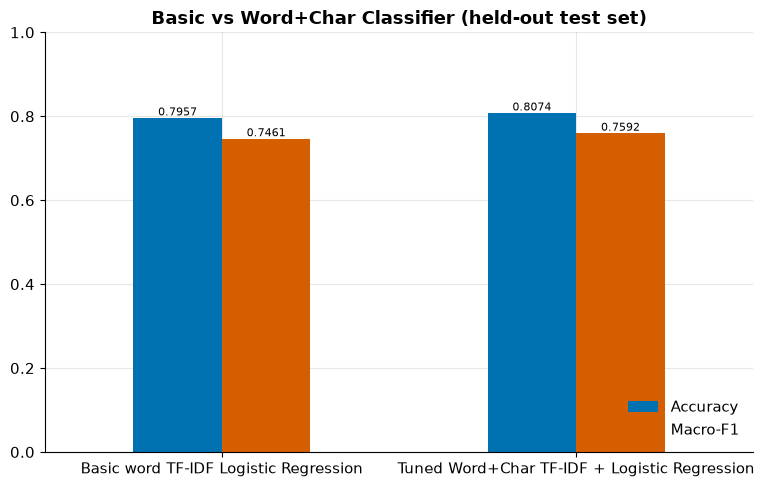

Accuracy gain: 1.17 percentage points | Macro-F1 gain: 0.0132


In [7]:
# Improvement over the basic model
ax = all_results[["accuracy", "macro_f1"]].plot(kind="bar", color=[PRIMARY_COLOR, SENTIMENT_COLORS["Negative"]], figsize=(8, 5))
ax.set_ylim(0, 1)
ax.set_title("Basic vs Word+Char Classifier (held-out test set)")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
ax.legend(["Accuracy", "Macro-F1"], loc="lower right")
for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", fontsize=8)
plt.tight_layout()
plt.show()

gain = (final_row["accuracy"] - basic_row["accuracy"]) * 100
print(f"Accuracy gain: {gain:.2f} percentage points | Macro-F1 gain: {final_row['macro_f1'] - basic_row['macro_f1']:.4f}")

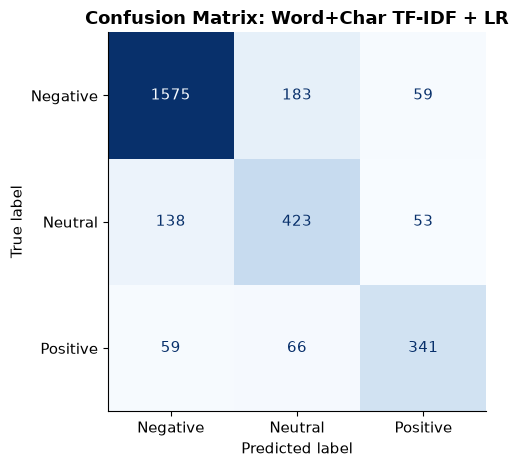

In [8]:
fig, ax = plt.subplots(figsize=(5.5, 4.8))
ConfusionMatrixDisplay.from_predictions(y_test, test_predictions, labels=SENTIMENT_LABELS,
                                        cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Confusion Matrix: Word+Char TF-IDF + LR")
ax.grid(False)
plt.tight_layout()
plt.show()

**Reading the confusion matrix:** Negative is recognised best. Most errors are between **Negative and Neutral**. Enquiries ("can you help me rebook?") and mild complaints share vocabulary, so this is the hardest boundary. Positive and Negative are rarely confused with each other.

### 4.1 How Stable Is the Score Across Random Splits?

Test scores depend on **which 2,897 tweets** land in the test set, so the experiment is repeated on 10 random 80/20 splits.

**Avoiding tuning leakage.** Reusing the hyperparameters chosen on the seed-42 training split would be slightly optimistic: that training split overlaps the *test* sets of the other seeds, so the chosen `C` would have "seen" some of the tweets it is later scored on. Instead, `src.evaluation.repeated_split_evaluation` re-runs a 3-fold grid search over `C` **inside each seed's training split**, refits the best model and scores it once on that seed's test split. The feature design (word 1–2-grams + character 3–5-grams) is kept fixed.

In [9]:
stability = repeated_split_evaluation(df, build_word_char_lr, {"model__C": [0.5, 1, 2]}, seeds=range(10))
display(stability[["seed", "model__C", "accuracy", "macro_f1"]].round(4))
stability[["accuracy", "macro_f1"]].agg(["mean", "std", "min", "max"]).round(4)

,seed,model__C,accuracy,macro_f1
0,0,1.0,0.8119,0.7673
1,1,1.0,0.8143,0.7708
2,2,1.0,0.8112,0.7655
3,3,1.0,0.8174,0.7749
4,4,2.0,0.8015,0.7521
5,5,0.5,0.8046,0.7619
6,6,1.0,0.8029,0.7505
7,7,1.0,0.8036,0.7586
8,8,0.5,0.8060,0.7582
9,9,1.0,0.8074,0.7642


,accuracy,macro_f1
mean,0.8081,0.7624
std,0.0053,0.0078
min,0.8015,0.7505
max,0.8174,0.7749


**Interpretation:** the selected `C` and the scores vary from split to split, which is why the model's performance is reported as a mean ± standard deviation rather than a single exact number.

### 4.2 Ablation: Does Removing @Handles Hurt?

The pipeline's first step removes @mentions to stop the model from learning airline identity. Re-training the same model on the **raw** text shows the effect of that choice.

In [10]:
best_C = grid_search.best_params_["model__C"]
best_ngrams = grid_search.best_params_["features__word__ngram_range"]

# Same features and classifier, but no cleaning step: handles and URLs stay in the text
raw_model = Pipeline([("features", word_char_tfidf(best_ngrams)), ("model", balanced_logistic_regression(best_C))])
raw_model.fit(X_train, y_train)
raw_predictions = raw_model.predict(X_test)

ablation = pd.DataFrame([
    {"input": "Raw text (handles + URLs kept)", **score_predictions(y_test, raw_predictions)},
    {"input": "Cleaned text (handles + URLs removed)", **score_predictions(y_test, test_predictions)},
]).set_index("input")[["accuracy", "macro_f1"]]
ablation.round(4)

,accuracy,macro_f1
input,,
Raw text (handles + URLs kept),0.8101,0.7628
Cleaned text (handles + URLs removed),0.8074,0.7592


**Interpretation:** keeping handles and URLs gives a marginal gain on this split (about +0.004 macro-F1 and +0.3 accuracy points), which is smaller than the split-to-split variation measured in section 4.1 (standard deviation ≈ 0.008 macro-F1). Part of any such gain can come from airline identity: the airlines have very different Negative rates (notebook 05), so a handle acts as a prior. The cleaned version is kept because it predicts from what customers write rather than which airline they tag, which is the more defensible behaviour for new tweets.

### 4.3 Advanced Model by Airline

In [11]:
advanced_by_airline = test_df.assign(predicted=test_predictions).groupby("airline").apply(
    lambda g: pd.Series({
        "test_tweets": len(g),
        "accuracy": accuracy_score(g["airline_sentiment"], g["predicted"]),
        "macro_f1": f1_score(g["airline_sentiment"], g["predicted"], average="macro"),
    }),
    include_groups=False,
).astype({"test_tweets": int}).sort_values("macro_f1", ascending=False)
advanced_by_airline.round(4)

,test_tweets,accuracy,macro_f1
airline,,,
American,513,0.8558,0.7799
JetBlue,460,0.7804,0.7758
Southwest,493,0.7647,0.7484
US Airways,581,0.8399,0.7434
United,763,0.8113,0.7394
Virgin America,87,0.6552,0.6386


## 5. Business Application: Suggesting Categories for "Can't Tell" Complaints

13% of complaints are labelled **"Can't Tell"** (notebook 04), so they cannot be routed to a team. A second text classifier is trained on complaints that **do** have a category and then used to **suggest** a category for each "Can't Tell" tweet.

These suggestions are model outputs for triage. They do not change the dataset's labels.

In [12]:
categorised = df[(df["airline_sentiment"] == "Negative") & (df["negativereason"] != "Can't Tell")]
cant_tell = df[df["negativereason"] == "Can't Tell"]

reason_train, reason_test = split_train_test(categorised, target="negativereason")
reason_model = build_word_char_lr(C=2).fit(reason_train["text"], reason_train["negativereason"])
reason_predictions = reason_model.predict(reason_test["text"])

print(f"Complaint-category model ({categorised['negativereason'].nunique()} categories)")
reason_scores = score_predictions(reason_test["negativereason"], reason_predictions)
print(f"Test accuracy: {reason_scores['accuracy']:.4f}")
print(f"Test macro-F1: {reason_scores['macro_f1']:.4f}")
print()
print(classification_report(reason_test["negativereason"], reason_predictions, digits=3, zero_division=0))

Complaint-category model (9 categories)
Test accuracy: 0.6759
Test macro-F1: 0.5827

                             precision    recall  f1-score   support

                 Bad Flight      0.521     0.643     0.576       115
           Cancelled Flight      0.783     0.741     0.762       166
     Customer Service Issue      0.776     0.667     0.717       576
            Damaged Luggage      0.750     0.400     0.522        15
Flight Attendant Complaints      0.392     0.495     0.437        95
    Flight Booking Problems      0.496     0.606     0.545       104
                Late Flight      0.726     0.779     0.751       330
                 Long Lines      0.286     0.171     0.214        35
               Lost Luggage      0.692     0.750     0.720       144

                   accuracy                          0.676      1580
                  macro avg      0.602     0.584     0.583      1580
               weighted avg      0.687     0.676     0.678      1580



In [13]:
# Apply to the "Can't Tell" complaints, keeping only confident suggestions
cant_tell_probabilities = reason_model.predict_proba(cant_tell["text"])
suggestions = pd.DataFrame({
    "suggested_category": reason_model.classes_[cant_tell_probabilities.argmax(axis=1)],
    "confidence": cant_tell_probabilities.max(axis=1),
})

CONFIDENCE_THRESHOLD = 0.6
confident = suggestions[suggestions["confidence"] >= CONFIDENCE_THRESHOLD]

print(f"'Can't Tell' complaints: {len(cant_tell):,}")
print(f"Suggestions with confidence >= {CONFIDENCE_THRESHOLD}: {len(confident):,} ({len(confident) / len(cant_tell) * 100:.1f}%)")
confident["suggested_category"].value_counts().to_frame("suggested_tweets")

'Can't Tell' complaints: 1,182
Suggestions with confidence >= 0.6: 112 (9.5%)


,suggested_tweets
suggested_category,
Customer Service Issue,28
Bad Flight,27
Flight Booking Problems,18
Lost Luggage,11
Late Flight,10
Flight Attendant Complaints,9
Cancelled Flight,6
Long Lines,2
Damaged Luggage,1


**Interpretation:** the category model is useful but imperfect. It is strongest on distinctive categories (Cancelled Flight, Late Flight, Customer Service Issue, Lost Luggage) and weak on small or overlapping ones (Long Lines, Flight Attendant Complaints). Only about 1 in 10 "Can't Tell" complaints receives a confident suggestion, so most of them are **genuinely ambiguous** rather than simply untagged. The realistic use is to route the confident minority automatically and leave the rest with a human reviewer. This supports Business Recommendation 6, and it also shows that better tagging at the source matters more than a model.

## 6. Demonstration: Predicting New Tweets

The trained pipeline accepts raw text, applies the same cleaning and returns class probabilities. The examples below are written for demonstration and are **not** part of the dataset.

In [14]:
predict_sentiment([
    "@united my flight got cancelled and nobody at the desk will help, 3 hours in line",
    "@SouthwestAir thank you for the amazing crew on flight 1234, best trip ever!",
    "@AmericanAir what is the baggage allowance for international flights?",
    "@JetBlue not happy that my bag is still missing after two days",
], final_model)

,text,predicted,Negative,Neutral,Positive
0,@united my flight got cancelled and nobody at ...,Negative,0.884,0.063,0.054
1,@SouthwestAir thank you for the amazing crew o...,Positive,0.000,0.000,1.000
2,@AmericanAir what is the baggage allowance for...,Neutral,0.053,0.937,0.010
3,@JetBlue not happy that my bag is still missin...,Negative,0.993,0.003,0.004


## 7. Conclusions

In [15]:
best_params = grid_search.best_params_
print(f"1. Word+char model: C={best_params['model__C']}, word n-grams {best_params['features__word__ngram_range']}.")
print(f"2. Held-out test: accuracy {final_row['accuracy']:.4f}, macro-F1 {final_row['macro_f1']:.4f}, "
      f"weighted-F1 {final_row['weighted_f1']:.4f} (basic word model macro-F1 {basic_row['macro_f1']:.4f}).")
print(f"3. Across 10 random splits (C re-tuned inside each training split): accuracy "
      f"{stability['accuracy'].mean():.4f} +/- {stability['accuracy'].std():.4f}, "
      f"macro-F1 {stability['macro_f1'].mean():.4f} +/- {stability['macro_f1'].std():.4f}.")
print(f"4. Improvement over the basic word model: {gain:.2f} accuracy points, "
      f"{final_row['macro_f1'] - basic_row['macro_f1']:.4f} macro-F1.")
print(f"5. Handle/URL removal: cleaned text macro-F1 {final_row['macro_f1']:.4f} vs raw text "
      f"{ablation.loc['Raw text (handles + URLs kept)', 'macro_f1']:.4f}.")

1. Word+char model: C=2, word n-grams (1, 2).
2. Held-out test: accuracy 0.8074, macro-F1 0.7592, weighted-F1 0.8093 (basic word model macro-F1 0.7461).
3. Across 10 random splits (C re-tuned inside each training split): accuracy 0.8081 +/- 0.0053, macro-F1 0.7624 +/- 0.0078.
4. Improvement over the basic word model: 1.17 accuracy points, 0.0132 macro-F1.
5. Handle/URL removal: cleaned text macro-F1 0.7592 vs raw text 0.7628.


**Key takeaways**

1. **Character features help.** Combining word and character TF-IDF improves on the word-only model, because character n-grams cope with misspellings, slang and hashtags.
2. **About 81% accuracy and 0.76 Macro-F1** on three classes (10-split mean 0.808 ± 0.005 accuracy, 0.762 ± 0.008 macro-F1, with `C` re-tuned inside each training split). Scores are reported as a range, not a single exact number.
3. **Neutral remains the hardest class.** Most errors fall on the Negative ↔ Neutral boundary.
4. **Handles are not needed.** Removing @handles and URLs costs at most a marginal amount (within split-to-split noise) and keeps the model from leaning on airline identity.
5. **Practical use:** triage of new tweets and category suggestions for a minority of "Can't Tell" complaints, with humans reviewing low-confidence cases.

**Limitations:** TF-IDF ignores context beyond two-word phrases and cannot read sarcasm. Probabilities are not calibrated. The data covers one week of 2015. Transformer models (BERT, RoBERTa) are a possible future comparison and should be judged on the same metrics, not assumed to be better.